In [ ]:
%matplotlib inline
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from decovaefm.cli import getparser
from decovaefm.debug_data import DummyRandomDataset
from scripts.train import train
from types import SimpleNamespace
import matplotlib.pyplot as plt
import torch
import numpy as np

Task was destroyed but it is pending!
task: <Task pending name='Task-162' coro=<_async_in_context.<locals>.run_in_context() done, defined at /app/.venv/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-163' coro=<Kernel.shell_main() running at /app/.venv/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /app/.venv/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
/app/.venv/lib/python3.11/site-packages/matplotlib/artist.py:1072: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  if alpha is not None and not isinstance(alpha, Real):
Task was destroyed but it is pending!
task: <Task pending name='Task-163' coro=<Kernel.shell_main() running at /app/.venv/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


In [2]:
parser = getparser()
defaults_dict = vars(parser.parse_args([]))
defaults_dict

{'context_len': 512,
 'pred_len': 96,
 'batch_size': 32,
 'data_dir': './data',
 'datasets': None,
 'load_fraction': 1.0,
 'load_seed': 42,
 'window_stride': 96,
 'stream_from_disk': False,
 'debug_on_dummy': False,
 'num_workers': 0,
 'd_model': 64,
 'patch_size': 16,
 'stride': 16,
 'n_heads': 4,
 'enc_layers': 2,
 'dec_layers': 2,
 'k_top': 16,
 'rope_theta': 10000.0,
 'kernels': [5, 9, 13, 25],
 'epochs': 10,
 'early_stopping_patience': 5,
 'viz_enabled': True,
 'viz_num_forecasts': 8,
 'viz_seed': 42,
 'devices': 'auto',
 'accelerator': 'cpu',
 'learning_rate': 0.0001,
 'kl_weight': 0.01,
 'recon_weight': 1.0,
 'forecast_weight': 1.0}

In [3]:
args = SimpleNamespace(**defaults_dict)
args.pred_len = 256
args.load_seed = 1

In [4]:
ds = DummyRandomDataset(
    num_samples=4,
    context_len=args.context_len,
    pred_len=args.pred_len,
    seed=args.load_seed,
)
for i in range(len(ds)):
    plt.figure(figsize=(10,2))
    plt.plot(range(args.context_len), ds.context[i])
    plt.plot(range(args.context_len, args.context_len + args.pred_len), ds.target[i])
    plt.show()

In [5]:
args.debug_on_dummy = True
args.epochs = 30
args.devices = 1
args.accelerator = "gpu"
args.kl_weight = 1.
args.learning_rate = 0.001
args.d_model = 64
#args.kernels = [125]
model = train(args)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
/app/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Train samples: 2048
Val samples: 256
Creating model...

Starting training...


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]

  | Name  | Type      | Params | Mode  | FLOPs
----------------------------------------------------
0 | model | DecoVAEFM | 315 K  | train | 0    
----------------------------------------------------
315 K     Trainable params
0         Non-trainable params
315 K     Total params
1.264     Total estimated model params size (MB)
93        Modules in train mode
0         Modules in eval mode
0         Total Flops


Forecast viz: cached 8 val windows (seed=42) -> outputs/notebook/forecasts


Sanity Checking: |                                                                   | 0/? [00:00<?, ?it/s]

...

Validation: |                                                                        | 0/? [00:00<?, ?it/s]

Validation: |                                                                        | 0/? [00:00<?, ?it/s]

Validation: |                                                                        | 0/? [00:00<?, ?it/s]

Validation: |                                                                        | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=30` reached.


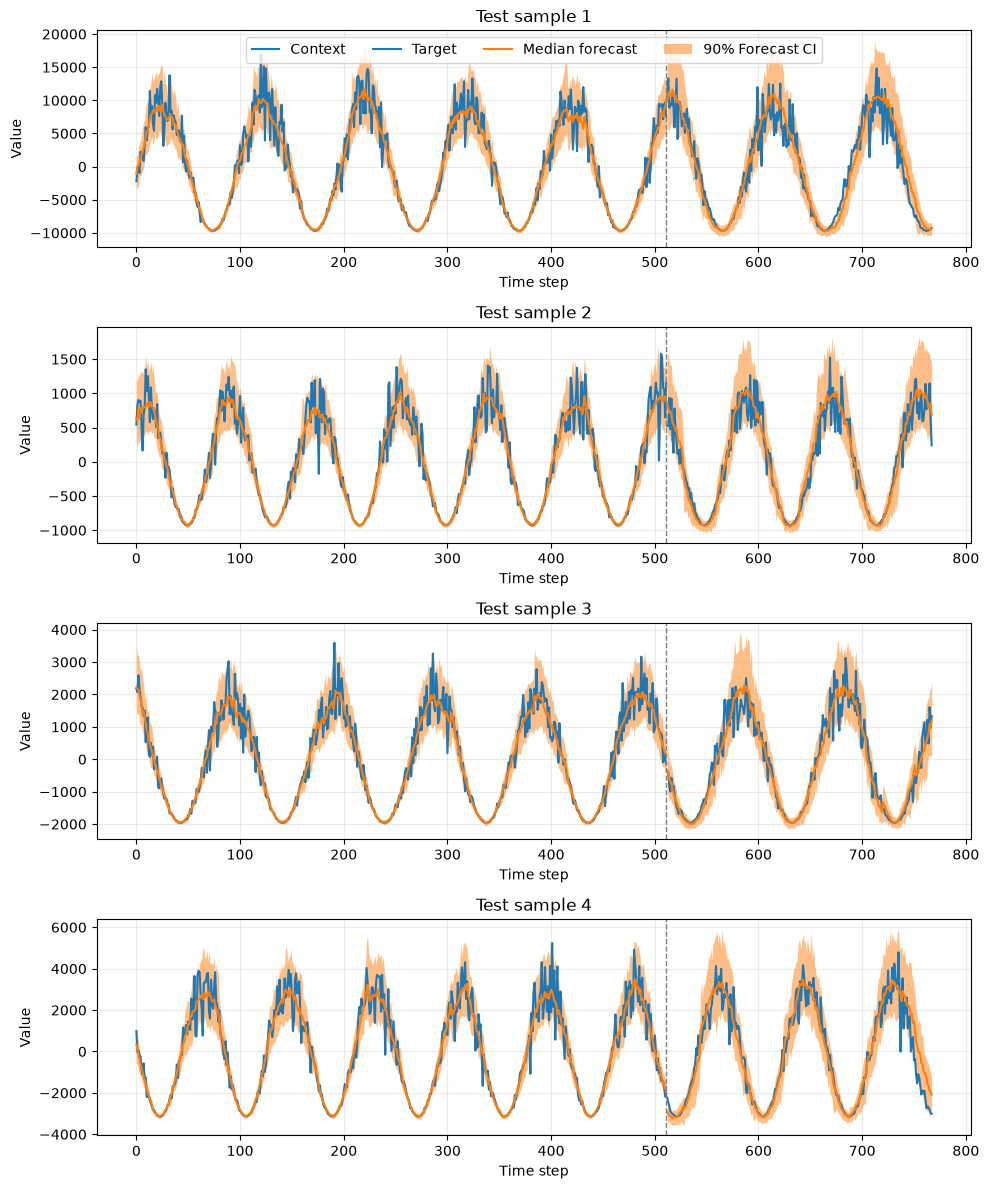

In [16]:
model.eval()
with torch.no_grad():
    prediction = model.predict_step((ds.context, ds.target), batch_idx=0)
    forecast_samples = prediction["forecast_samples"]  # (batch, num_samples, pred_len)
    recon_samples = prediction["recon_samples"]
    target = prediction["target"]

forecast_median = torch.quantile(forecast_samples, 0.5, dim=1)
forecast_q05 = torch.quantile(forecast_samples, 0.05, dim=1)
forecast_q95 = torch.quantile(forecast_samples, 0.95, dim=1)

recon_median = torch.quantile(recon_samples, 0.5, dim=1)
recon_q05 = torch.quantile(recon_samples, 0.05, dim=1)
recon_q95 = torch.quantile(recon_samples, 0.95, dim=1)

n = ds.context.shape[0]
n_cols = 1
n_rows = int(np.ceil(n / n_cols))

plt.figure(figsize=(10, 3 * n_rows))

for i in range(n):
    plt.subplot(n_rows, n_cols, i+1)

    context = ds.context[i].numpy()
    target = ds.target[i].numpy()
    r_median = recon_median[i].numpy()
    r_q05 = recon_q05[i].numpy()
    r_q95 = recon_q95[i].numpy()
    f_median = forecast_median[i].numpy()
    f_q05 = forecast_q05[i].numpy()
    f_q95 = forecast_q95[i].numpy()

    x_context = range(args.context_len)
    x_forecast = range(args.context_len, args.context_len + args.pred_len)

    plt.plot(x_context, context, label="Context", color="tab:blue")
    plt.plot(x_context, r_median, color="tab:orange")
    plt.fill_between(x_context, r_q05, r_q95, color="tab:orange", alpha=0.5, linewidth=0)
    plt.plot(x_forecast, target, label="Target", color="tab:blue")
    plt.plot(x_forecast, f_median, label="Median forecast", color="tab:orange")
    plt.fill_between(x_forecast, f_q05, f_q95, color="tab:orange", alpha=0.5, label="90% Forecast CI", linewidth=0)

    plt.axvline(args.context_len - 1, color="gray", linestyle="--", linewidth=1)
    plt.title(f"Test sample {i + 1}")
    plt.xlabel("Time step")
    plt.ylabel("Value")
    plt.grid(alpha=0.25)
    if i == 0:
        plt.legend(loc="upper center", ncol=4)

plt.tight_layout()
plt.show()

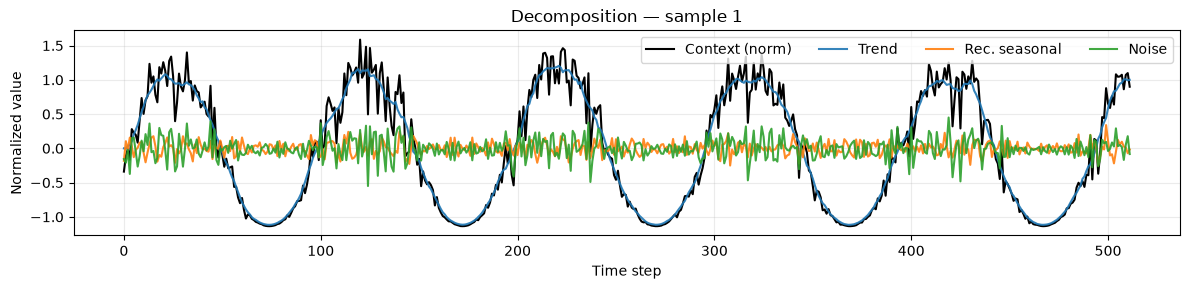

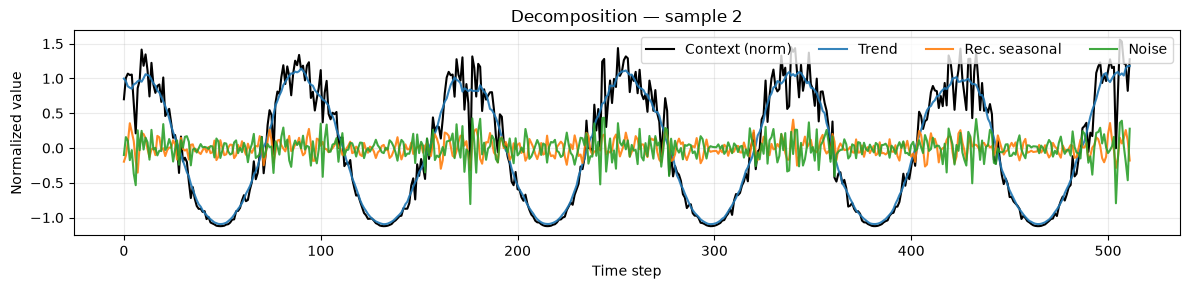

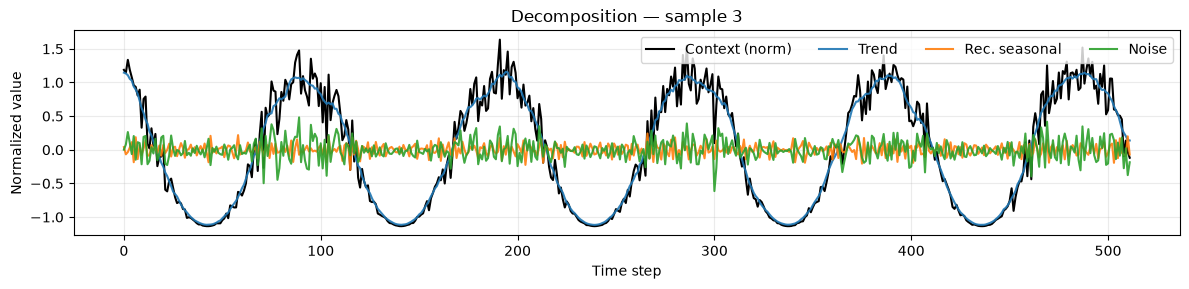

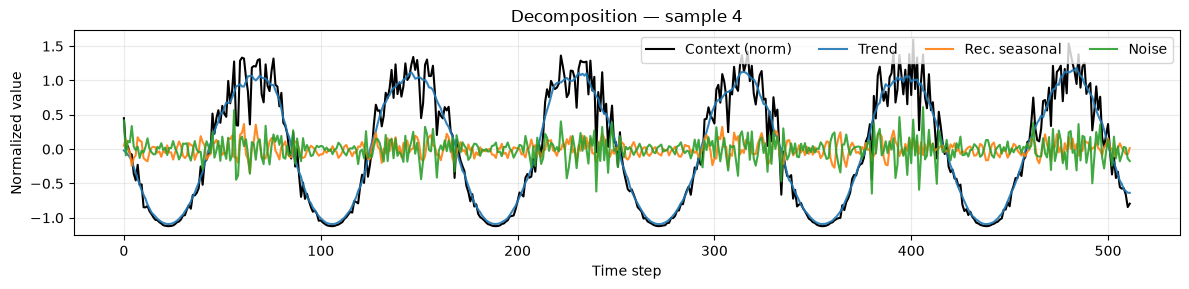

In [14]:
# Decomposition: context vs trend / seasonal / noise (normalized space)
core = model.model
device = next(core.parameters()).device
x = ds.context.to(device)
y = ds.target.to(device)

x_mean, x_std = model._get_normalization_stats(x)
x_norm = model._normalize(x, x_mean, x_std)

with torch.no_grad():
    enc = core.encode(x_norm)
    trend = enc["target_trend"]
    rec_seasonal = enc["target_seasonal"]
    noise = x_norm - trend - rec_seasonal

n = x.shape[0]
for i in range(n):
    fig, ax = plt.subplots(figsize=(12, 3))
    t = np.arange(args.context_len)
    ax.plot(t, x_norm[i].cpu().numpy(), label="Context (norm)", color="black", lw=1.5)
    ax.plot(t, trend[i].cpu().numpy(), label="Trend", color="tab:blue", alpha=0.9)
    ax.plot(t, rec_seasonal[i].cpu().numpy(), label="Rec. seasonal", color="tab:orange", alpha=0.9)
    ax.plot(t, noise[i].cpu().numpy(), label="Noise", color="tab:green", alpha=0.9)
    ax.set_title(f"Decomposition — sample {i + 1}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Normalized value")
    ax.legend(loc="upper right", ncol=4)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


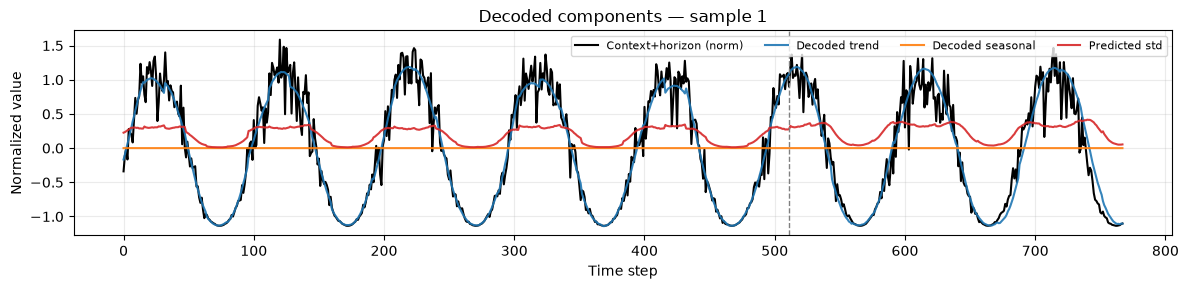

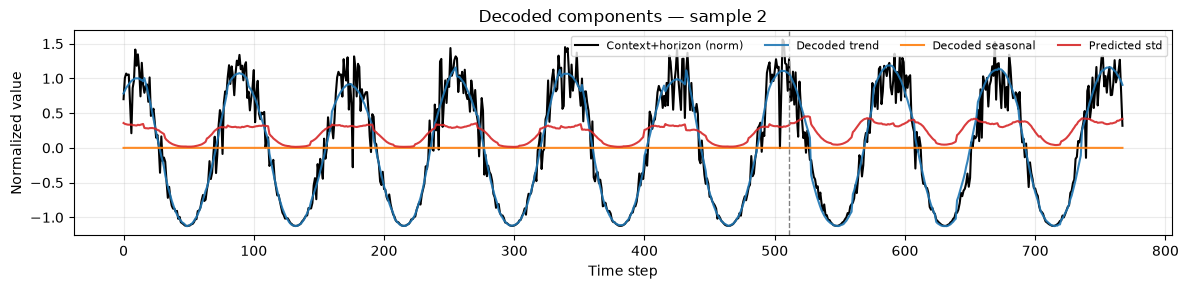

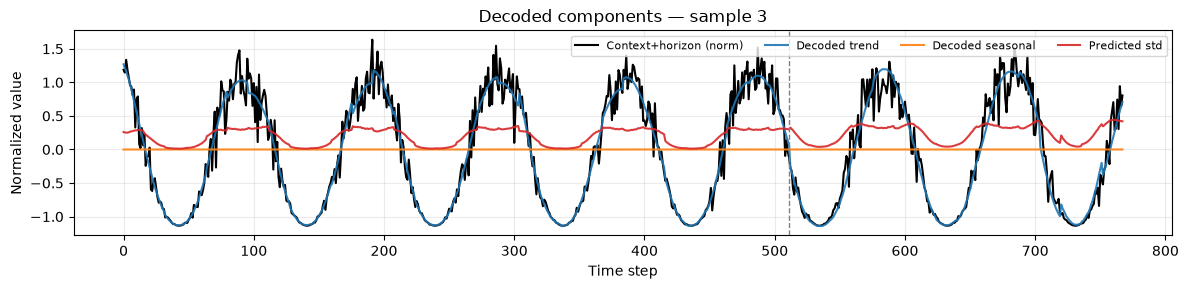

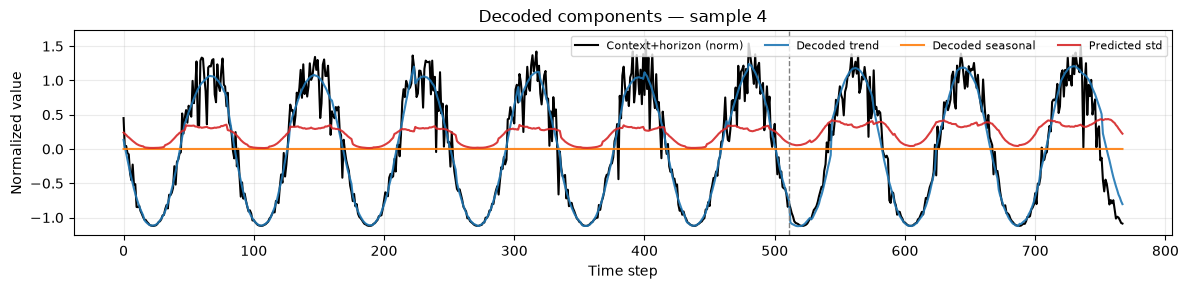

In [15]:
# Predictions: context+horizon vs decoded trend / seasonal / std from model.forward
L = args.pred_len
T = args.context_len
y_norm = model._normalize(y, x_mean, x_std)
full_norm = torch.cat([x_norm, y_norm], dim=1)

with torch.no_grad():
    # Deterministic decode at posterior means (same path as training, no reparam noise).
    # Temporarily replace reparameterize so forward returns mean-decoded components.
    _reparameterize = core.reparameterize
    core.reparameterize = lambda mu, logvar: mu
    try:
        out = core(x_norm, pred_len=L)
    finally:
        core.reparameterize = _reparameterize

    pred_trend = out["decoded_trend"]
    pred_seasonal = out["decoded_seasonal"]
    pred_std = (0.5 * out["decoded_logvar"]).exp()
    target_trend = out["target_trend"]
    target_seasonal = out["target_seasonal"]

for i in range(n):
    fig, ax = plt.subplots(figsize=(12, 3))

    t_ctx = np.arange(T)
    t_full = np.arange(T + L)

    ax.plot(t_full, full_norm[i].cpu().numpy(), label="Context+horizon (norm)", color="black", lw=1.5)
    ax.plot(t_full, pred_trend[i].cpu().numpy(), label="Decoded trend", color="tab:blue", alpha=0.9)
    ax.plot(t_full, pred_seasonal[i].cpu().numpy(), label="Decoded seasonal", color="tab:orange", alpha=0.9)
    ax.plot(t_full, pred_std[i].cpu().numpy(), label="Predicted std", color="tab:red", alpha=0.9)
    ax.axvline(T - 1, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Decoded components — sample {i + 1}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Normalized value")
    ax.legend(loc="upper right", ncol=4, fontsize=8)
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()
